# Liver Disease Classification
Executed educational comparison of a majority baseline, logistic regression and an RBF SVM on UCI ILPD data.
See README.md for results and limitations, and PERSONAL_CONTRIBUTION.md for contribution and assistance details.
This notebook retains the executed analysis and its outputs; code and reported metrics are unchanged.


## 1. Set up the environment
Run this cell to install the required packages. A CPU runtime is sufficient.

**Expected output:** Installation completes without an exception.

**Review:** If installation fails, share the full error before continuing.


In [1]:
%pip -q install pandas numpy scipy scikit-learn matplotlib joblib

## 2. Import tools and record versions
Import the analysis tools and create the output folders.

**Expected output:** Python and package versions are printed, followed by CHECKPOINT 1.

**Review:** Continue unless an import fails; share any full traceback.


In [2]:
from pathlib import Path
import io, json, hashlib, zipfile, platform, sys
from urllib.request import urlopen
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report)
import joblib

SEED = 42
ROOT = Path('liver_disease_project')
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
DATA.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
VERSIONS = {p: version(p) for p in
    ['numpy','pandas','scipy','scikit-learn','matplotlib','joblib']}
print('Python:', platform.python_version())
print(json.dumps(VERSIONS, indent=2))
print('CHECKPOINT 1: environment ready')

Python: 3.13.18
{
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1",
  "matplotlib": "3.10.0",
  "joblib": "1.6.0"
}
CHECKPOINT 1: environment ready


## 3. Download and inspect the original UCI dataset
Download the official UCI archive and record data provenance. This portfolio refresh uses the original source; it is not assumed to be byte-identical to an earlier course CSV.

**Expected output:** Row counts, original class counts, missing values and exact duplicates are printed.

**Review:** Share these four summaries before continuing. Use the actual file counts rather than inconsistent figures in the source-page description.

**Review checkpoint: pause here before continuing.**


In [3]:
SOURCE_PAGE = 'https://archive.ics.uci.edu/dataset/225/ilpd'
ZIP_URL = ('https://archive.ics.uci.edu/static/public/225/'
           'ilpd+indian+liver+patient+dataset.zip')
archive_path = DATA / 'uci_ilpd.zip'
if not archive_path.exists():
    try:
        archive_path.write_bytes(urlopen(ZIP_URL, timeout=60).read())
    except Exception as exc:
        raise RuntimeError('Download failed. Stop and share this error; do not substitute another CSV silently.') from exc
raw = archive_path.read_bytes()
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    csv_files = [n for n in z.namelist() if n.lower().endswith('.csv')]
    if len(csv_files) != 1:
        raise ValueError(f'Unexpected dataset archive contents: {csv_files}')
    csv_bytes = z.read(csv_files[0])

COLS = ['age','gender','total_bilirubin','direct_bilirubin',
        'alkaline_phosphotase','alanine_aminotransferase',
        'aspartate_aminotransferase','total_proteins','albumin',
        'albumin_globulin_ratio','selector']
df_raw = pd.read_csv(io.BytesIO(csv_bytes), header=None, names=COLS)
if df_raw.shape[1] != 11 or not (400 < len(df_raw) < 1000):
    raise ValueError(f'Unexpected shape: {df_raw.shape}. Stop and review the source.')
if not set(df_raw['selector'].dropna().unique()).issubset({1,2}):
    raise ValueError('Unexpected target encoding. Do not guess class meanings.')
df_raw.to_csv(DATA / 'ilpd_original.csv', index=False)
provenance = {
    'source_page': SOURCE_PAGE, 'download_url': ZIP_URL,
    'doi': '10.24432/C5D02C', 'license': 'CC BY 4.0',
    'archive_sha256': hashlib.sha256(raw).hexdigest(),
    'csv_sha256': hashlib.sha256(csv_bytes).hexdigest(),
    'retrieved_at_utc': datetime.now(timezone.utc).isoformat(),
    'raw_rows': int(len(df_raw)), 'raw_columns': int(df_raw.shape[1]),
    'target_mapping': {'1':'liver disease','2':'no liver disease'},
    'citation': 'Ramana, B. & Venkateswarlu, N. ILPD (Indian Liver Patient Dataset). UCI Machine Learning Repository.'
}
(RESULTS / 'data_provenance.json').write_text(json.dumps(provenance, indent=2))
print('Rows, columns:', df_raw.shape)
print('Original target counts:', df_raw['selector'].value_counts().to_dict())
print('Missing values:', df_raw.isna().sum().to_dict())
print('Exact duplicate rows:', int(df_raw.duplicated().sum()))
print('CHECKPOINT 2: data downloaded and inspected')

Rows, columns: (583, 11)
Original target counts: {1: 416, 2: 167}
Missing values: {'age': 0, 'gender': 0, 'total_bilirubin': 0, 'direct_bilirubin': 0, 'alkaline_phosphotase': 0, 'alanine_aminotransferase': 0, 'aspartate_aminotransferase': 0, 'total_proteins': 0, 'albumin': 0, 'albumin_globulin_ratio': 4, 'selector': 0}
Exact duplicate rows: 13
CHECKPOINT 2: data downloaded and inspected


## 4. Deduplicate and reserve the test partition
Remove exact duplicate records and separate the target from the features. Keep identical feature rows in the same partition. Missing-value handling is learned inside training pipelines.

**Expected output:** CHECKPOINT 3 confirms the split checks; the test partition remains reserved.

**Review:** Share split_summary.json or the printed summary. Stop if any assertion fails.

**Review checkpoint: pause here before continuing.**


In [4]:
df = df_raw.drop_duplicates().copy().reset_index(drop=True)
assert df['selector'].notna().all()
X = df.drop(columns='selector').copy()
y = df['selector'].map({1:1, 2:0}).astype(int)
assert 'selector' not in X.columns and X.shape[1] == 10
X['gender'] = X['gender'].astype(str).str.strip()
assert set(X['gender'].unique()).issubset({'Male','Female'})
NUMERIC = [c for c in X.columns if c != 'gender']
for col in NUMERIC:
    X[col] = pd.to_numeric(X[col], errors='raise')
assert not np.isinf(X[NUMERIC].to_numpy()).any()
# Group identical feature rows so they cannot occur in both partitions.
# These groups are a duplicate safeguard, not verified patient identifiers.
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(g_train).isdisjoint(set(g_test))
assert y_train.nunique() == y_test.nunique() == 2
assert set(train_idx).isdisjoint(set(test_idx))
split_info = {
    'raw_rows': len(df_raw), 'deduplicated_rows': len(df),
    'exact_duplicate_rows_removed': len(df_raw)-len(df),
    'training_rows': len(X_train), 'test_rows': len(X_test),
    'training_target_counts': {str(k):int(v) for k,v in y_train.value_counts().items()},
    'test_target_counts': {str(k):int(v) for k,v in y_test.value_counts().items()},
    'feature_count': X.shape[1], 'seed': SEED,
    'split': 'first fold of shuffled 5-fold StratifiedGroupKFold',
    'grouping': 'exact feature-row hashes; no verified patient IDs',
    'positive_class': 'liver disease (original Selector=1)',
    'duplicate_feature_groups_across_partitions': 0
}
(RESULTS/'split_summary.json').write_text(json.dumps(split_info, indent=2))
pd.DataFrame({'clean_row':np.arange(len(df)), 'group':groups,
    'partition':np.where(np.isin(np.arange(len(df)),test_idx),'test','train')
}).to_csv(RESULTS/'split_assignments.csv', index=False)
print(json.dumps(split_info, indent=2))
print('CHECKPOINT 3: split checks passed; test data reserved')

{
  "raw_rows": 583,
  "deduplicated_rows": 570,
  "exact_duplicate_rows_removed": 13,
  "training_rows": 456,
  "test_rows": 114,
  "training_target_counts": {
    "1": 328,
    "0": 128
  },
  "test_target_counts": {
    "1": 78,
    "0": 36
  },
  "feature_count": 10,
  "seed": 42,
  "split": "first fold of shuffled 5-fold StratifiedGroupKFold",
  "grouping": "exact feature-row hashes; no verified patient IDs",
  "positive_class": "liver disease (original Selector=1)",
  "duplicate_feature_groups_across_partitions": 0
}
CHECKPOINT 3: split checks passed; test data reserved


## 5. Compare models using training cross-validation
Compare a majority baseline, logistic regression and RBF SVM. Select the model using training-only cross-validation balanced accuracy, before inspecting test performance.

**Expected output:** A cross-validation table and the selected model name are printed.

**Review:** Share the table and selected model. Review the design before opening the held-out results.

**Review checkpoint: pause here before continuing.**


In [5]:
def make_pipeline(model):
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    prep = ColumnTransformer([('numeric',numeric,NUMERIC),
                              ('categorical',categorical,['gender'])])
    return Pipeline([('preprocess',prep),('model',model)])

inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_splits = list(inner.split(X_train, y_train, g_train))
for a,b in cv_splits:
    assert set(g_train.iloc[a]).isdisjoint(set(g_train.iloc[b]))
    assert y_train.iloc[a].nunique() == y_train.iloc[b].nunique() == 2

experiments = {
    'Majority baseline': (DummyClassifier(strategy='most_frequent'), {}),
    'Logistic regression': (LogisticRegression(max_iter=5000, random_state=SEED),
        {'model__C':[0.1,1,10], 'model__class_weight':[None,'balanced']}),
    'SVM': (SVC(kernel='rbf'),
        {'model__C':[0.1,1,10], 'model__gamma':['scale',0.01,0.1],
         'model__class_weight':[None,'balanced']})
}
searches = {}; cv_rows = []
for name,(model,grid) in experiments.items():
    search = GridSearchCV(make_pipeline(model), grid, scoring='balanced_accuracy',
        cv=cv_splits, n_jobs=1, refit=True, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    cv_rows.append({'model':name, 'cv_balanced_accuracy':float(search.best_score_),
        'cv_std':float(search.cv_results_['std_test_score'][search.best_index_]),
        'settings':json.dumps(search.best_params_)})
    pd.DataFrame(search.cv_results_).to_csv(
        RESULTS/('cv_'+name.lower().replace(' ','_')+'.csv'),index=False)
cv_table = pd.DataFrame(cv_rows).sort_values('cv_balanced_accuracy',ascending=False)
selected_name = str(cv_table.iloc[0]['model'])
cv_table.to_csv(RESULTS/'cross_validation_results.csv', index=False)
print(cv_table.to_string(index=False))
print('Selected using training CV only:', selected_name)
print('CHECKPOINT 4: model selected before test evaluation')

              model  cv_balanced_accuracy   cv_std                                                                  settings
Logistic regression              0.707549 0.021570                      {"model__C": 0.1, "model__class_weight": "balanced"}
                SVM              0.700803 0.004811 {"model__C": 10, "model__class_weight": "balanced", "model__gamma": 0.01}
  Majority baseline              0.500000 0.000000                                                                        {}
Selected using training CV only: Logistic regression
CHECKPOINT 4: model selected before test evaluation


## 6. Evaluate on the held-out test partition
Run after the analysis design is fixed. Report all three predeclared models without changing the cross-validation selection based on test results.

**Expected output:** A metric table, confusion matrices and classification report are produced.

**Review:** Share the table, figure and report. Do not repeatedly tune against this test partition.

**Review checkpoint: pause here before continuing.**


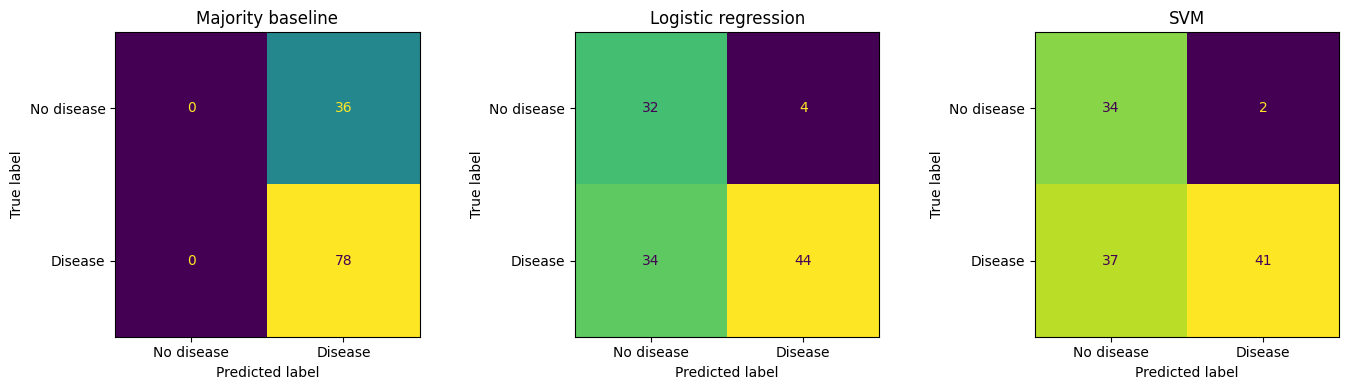

              model  selected_by_training_cv  accuracy  balanced_accuracy  precision_disease  recall_disease  f1_disease  roc_auc  average_precision
  Majority baseline                    False    0.6842             0.5000             0.6842          1.0000      0.8125   0.5000             0.6842
Logistic regression                     True    0.6667             0.7265             0.9167          0.5641      0.6984   0.7817             0.9063
                SVM                    False    0.6579             0.7350             0.9535          0.5256      0.6777   0.7867             0.9076
Frozen selection: Logistic regression
              precision    recall  f1-score   support

  No disease       0.48      0.89      0.63        36
     Disease       0.92      0.56      0.70        78

    accuracy                           0.67       114
   macro avg       0.70      0.73      0.66       114
weighted avg       0.78      0.67      0.68       114

CHECKPOINT 5: held-out evaluation compl

In [6]:
test_rows = []; preds_by_model = {}; scores_by_model = {}
for name,search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)
    if hasattr(model,'decision_function'):
        score = model.decision_function(X_test)
    else:
        score = model.predict_proba(X_test)[:,list(model.classes_).index(1)]
    preds_by_model[name] = pred; scores_by_model[name] = score
    test_rows.append({'model':name, 'selected_by_training_cv':name==selected_name,
        'accuracy':accuracy_score(y_test,pred),
        'balanced_accuracy':balanced_accuracy_score(y_test,pred),
        'precision_disease':precision_score(y_test,pred,zero_division=0),
        'recall_disease':recall_score(y_test,pred,zero_division=0),
        'f1_disease':f1_score(y_test,pred,zero_division=0),
        'roc_auc':roc_auc_score(y_test,score),
        'average_precision':average_precision_score(y_test,score)})
test_table = pd.DataFrame(test_rows)
test_table.to_csv(RESULTS/'test_metrics.csv',index=False)
fig,axes = plt.subplots(1,3,figsize=(14,4))
for ax,(name,pred) in zip(axes,preds_by_model.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred,labels=[0,1]),
        display_labels=['No disease','Disease']).plot(ax=ax,colorbar=False)
    ax.set_title(name)
fig.tight_layout(); fig.savefig(RESULTS/'confusion_matrices.png',dpi=160)
plt.show()
pd.DataFrame({'clean_row':test_idx, 'observed_disease':y_test.to_numpy(),
    'predicted_disease':preds_by_model[selected_name],
    'decision_score':scores_by_model[selected_name]}
).to_csv(RESULTS/'held_out_predictions.csv',index=False)
report = classification_report(y_test,preds_by_model[selected_name],
    labels=[0,1],target_names=['No disease','Disease'],zero_division=0)
(RESULTS/'classification_report.txt').write_text(report)
print(test_table.round(4).to_string(index=False))
print('Frozen selection:',selected_name)
print(report)
print('CHECKPOINT 5: held-out evaluation complete')

## 7. Save the model and reproducible reporting package
Save and reload the selected model, check predictions, record package versions and generate the README. Existing personal contribution notes are preserved.

**Expected output:** CHECKPOINT 6 confirms saved outputs. The rerun script is exported.

**Review:** Complete PERSONAL_CONTRIBUTION.md using your actual work and interpretation before a final public release.


In [7]:
final_model = searches[selected_name].best_estimator_
joblib.dump(final_model, RESULTS/'selected_model.joblib')
reloaded = joblib.load(RESULTS/'selected_model.joblib')
assert np.array_equal(reloaded.predict(X_test),preds_by_model[selected_name])
(ROOT/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in VERSIONS.items())+'\n')
(RESULTS/'environment.json').write_text(json.dumps(
    {'python':platform.python_version(),'packages':VERSIONS,'seed':SEED},indent=2))
selected = test_table.loc[test_table['model']==selected_name].iloc[0]
metrics_md = test_table.round(4).to_csv(index=False)
readme = f'''# Liver Disease Classification

Reproducible educational reimplementation of an earlier ML for Bioinformatics
course project, comparing a majority baseline, logistic regression and RBF SVM.
The current workflow and guide were prepared with AI assistance; Sara's final
contribution and interpretation are documented in PERSONAL_CONTRIBUTION.md.
Do not describe this as independent clinical research or clinical deployment.

## Question
How do these predeclared classifiers compare on held-out ILPD records under
training-only preprocessing and cross-validation?

## Data and credit
UCI ILPD, DOI: 10.24432/C5D02C. Ramana, B. & Venkateswarlu, N.
Source: {SOURCE_PAGE}
Dataset licence: CC BY 4.0; dataset citation does not license third-party code.
The original course notebook is not redistributed in this package.
Downloaded {len(df_raw)} rows; retained {len(df)} after exact-row deduplication.
Target: original Selector=1 means liver disease and Selector=2 means no disease.
Data hash and retrieval details: results/data_provenance.json.

## Evaluation
Feature-identical rows are grouped across an approximately 80/20 split.
No patient identifiers are available; this does not guarantee patient-level independence.
Three-fold grouped stratified CV on training records tunes preprocessing/model
pipelines and selects by mean balanced accuracy. Missing values and scaling are
learned only within training folds. The target is excluded from all features.
No decision threshold is tuned against the test set.
Training rows: {len(X_train)}; held-out rows: {len(X_test)}.
Selected before test evaluation: **{selected_name}**.
CV standard deviations are fold dispersion, not confidence intervals.

## Held-out results
```csv
{metrics_md}```

![Confusion matrices](results/confusion_matrices.png)

## Limitations
Small historical single-region dataset; class imbalance; no external validation,
no verified patient grouping, no confidence intervals or clinical utility study.
Results describe one fixed split; no diagnostic or deployment claim is made.
Any previous exposure to this dataset limits how novel this holdout can be considered.

## Rerun
Python 3.12 was used for the starter validation; the actual runtime version
for your run is recorded in results/environment.json.
Install requirements.txt, then run liver_disease_classification.py in an empty
working folder or open the included notebook in Colab and run its cells in order.
Internet is required for the public UCI download. No GPU is needed.
Download outputs before a temporary Colab runtime ends. Only load joblib files
from trusted sources. The saved model is optional to publish.
'''
(ROOT/'README.md').write_text(readme,encoding='utf-8')
contribution = '''# Personal contribution and interpretation

This is a new portfolio refresh of earlier coursework. The starter code and
guide were prepared with AI assistance; project execution and interpretation
must be documented below before a final public release.

Sara: replace the questions below with your own short factual answers.
1. What did you implement in the original coursework?
2. Which parts of this refresh did you inspect, modify and execute?
3. Explain why the target must not appear among features.
4. Explain why imputation and scaling belong inside training folds.
5. Which model was selected by CV, and what do its test results mean?
6. What error pattern and limitation matter most?
7. What would you improve next without tuning against this test set?

Keep assistance and source credits accurate. Do not claim sole authorship of
provided code. Remove these unanswered prompts only after writing your answers.
'''
contribution_path = ROOT/'PERSONAL_CONTRIBUTION.md'
if not contribution_path.exists():
    contribution_path.write_text(contribution,encoding='utf-8')
(ROOT/'.gitignore').write_text('data/\n__pycache__/\n.ipynb_checkpoints/\n*.zip\n')
checks = {'target_excluded': 'selector' not in X.columns,
    'no_feature_group_overlap':set(g_train).isdisjoint(set(g_test)),
    'model_reload_predictions_identical':True,
    'selected_by_training_cv':selected_name,
    'training_rows':len(X_train),'test_rows':len(X_test),
    'evaluation_run_utc':datetime.now(timezone.utc).isoformat()}
(RESULTS/'checks.json').write_text(json.dumps(checks,indent=2))
print(json.dumps(checks,indent=2))
print('CHECKPOINT 6: outputs saved; personal interpretation still required')

(ROOT/"liver_disease_classification.py").write_text('"""Educational ILPD comparison. See README and provenance; not for clinical use.\nStarter workflow prepared with AI assistance for Sara\'s guided portfolio refresh.\n"""\n\n# 2. Import tools and record versions\nfrom pathlib import Path\nimport io, json, hashlib, zipfile, platform, sys\nfrom urllib.request import urlopen\nfrom datetime import datetime, timezone\nfrom importlib.metadata import version\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom sklearn.model_selection import StratifiedGroupKFold, GridSearchCV\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.dummy import DummyClassifier\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.svm import SVC\nfrom sklearn.metrics import (balanced_accuracy_score, precision_score, recall_score,\n    f1_score, roc_auc_score, average_precision_score, accuracy_score,\n    confusion_matrix, ConfusionMatrixDisplay, classification_report)\nimport joblib\n\nSEED = 42\nROOT = Path(\'liver_disease_project\')\nDATA = ROOT / \'data\'\nRESULTS = ROOT / \'results\'\nDATA.mkdir(parents=True, exist_ok=True)\nRESULTS.mkdir(parents=True, exist_ok=True)\nVERSIONS = {p: version(p) for p in\n    [\'numpy\',\'pandas\',\'scipy\',\'scikit-learn\',\'matplotlib\',\'joblib\']}\nprint(\'Python:\', platform.python_version())\nprint(json.dumps(VERSIONS, indent=2))\nprint(\'CHECKPOINT 1: environment ready\')\n\n# 3. Download and inspect the original UCI dataset\nSOURCE_PAGE = \'https://archive.ics.uci.edu/dataset/225/ilpd\'\nZIP_URL = (\'https://archive.ics.uci.edu/static/public/225/\'\n           \'ilpd+indian+liver+patient+dataset.zip\')\narchive_path = DATA / \'uci_ilpd.zip\'\nif not archive_path.exists():\n    try:\n        archive_path.write_bytes(urlopen(ZIP_URL, timeout=60).read())\n    except Exception as exc:\n        raise RuntimeError(\'Download failed. Stop and share this error; do not substitute another CSV silently.\') from exc\nraw = archive_path.read_bytes()\nwith zipfile.ZipFile(io.BytesIO(raw)) as z:\n    csv_files = [n for n in z.namelist() if n.lower().endswith(\'.csv\')]\n    if len(csv_files) != 1:\n        raise ValueError(f\'Unexpected dataset archive contents: {csv_files}\')\n    csv_bytes = z.read(csv_files[0])\n\nCOLS = [\'age\',\'gender\',\'total_bilirubin\',\'direct_bilirubin\',\n        \'alkaline_phosphotase\',\'alanine_aminotransferase\',\n        \'aspartate_aminotransferase\',\'total_proteins\',\'albumin\',\n        \'albumin_globulin_ratio\',\'selector\']\ndf_raw = pd.read_csv(io.BytesIO(csv_bytes), header=None, names=COLS)\nif df_raw.shape[1] != 11 or not (400 < len(df_raw) < 1000):\n    raise ValueError(f\'Unexpected shape: {df_raw.shape}. Stop and review the source.\')\nif not set(df_raw[\'selector\'].dropna().unique()).issubset({1,2}):\n    raise ValueError(\'Unexpected target encoding. Do not guess class meanings.\')\ndf_raw.to_csv(DATA / \'ilpd_original.csv\', index=False)\nprovenance = {\n    \'source_page\': SOURCE_PAGE, \'download_url\': ZIP_URL,\n    \'doi\': \'10.24432/C5D02C\', \'license\': \'CC BY 4.0\',\n    \'archive_sha256\': hashlib.sha256(raw).hexdigest(),\n    \'csv_sha256\': hashlib.sha256(csv_bytes).hexdigest(),\n    \'retrieved_at_utc\': datetime.now(timezone.utc).isoformat(),\n    \'raw_rows\': int(len(df_raw)), \'raw_columns\': int(df_raw.shape[1]),\n    \'target_mapping\': {\'1\':\'liver disease\',\'2\':\'no liver disease\'},\n    \'citation\': \'Ramana, B. & Venkateswarlu, N. ILPD (Indian Liver Patient Dataset). UCI Machine Learning Repository.\'\n}\n(RESULTS / \'data_provenance.json\').write_text(json.dumps(provenance, indent=2))\nprint(\'Rows, columns:\', df_raw.shape)\nprint(\'Original target counts:\', df_raw[\'selector\'].value_counts().to_dict())\nprint(\'Missing values:\', df_raw.isna().sum().to_dict())\nprint(\'Exact duplicate rows:\', int(df_raw.duplicated().sum()))\nprint(\'CHECKPOINT 2: data downloaded and inspected\')\n\n# 4. Deduplicate and reserve the test partition\ndf = df_raw.drop_duplicates().copy().reset_index(drop=True)\nassert df[\'selector\'].notna().all()\nX = df.drop(columns=\'selector\').copy()\ny = df[\'selector\'].map({1:1, 2:0}).astype(int)\nassert \'selector\' not in X.columns and X.shape[1] == 10\nX[\'gender\'] = X[\'gender\'].astype(str).str.strip()\nassert set(X[\'gender\'].unique()).issubset({\'Male\',\'Female\'})\nNUMERIC = [c for c in X.columns if c != \'gender\']\nfor col in NUMERIC:\n    X[col] = pd.to_numeric(X[col], errors=\'raise\')\nassert not np.isinf(X[NUMERIC].to_numpy()).any()\n# Group identical feature rows so they cannot occur in both partitions.\n# These groups are a duplicate safeguard, not verified patient identifiers.\ngroups = pd.util.hash_pandas_object(X, index=False).astype(str)\nsplitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)\ntrain_idx, test_idx = next(splitter.split(X, y, groups))\nX_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()\ny_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()\ng_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]\nassert set(g_train).isdisjoint(set(g_test))\nassert y_train.nunique() == y_test.nunique() == 2\nassert set(train_idx).isdisjoint(set(test_idx))\nsplit_info = {\n    \'raw_rows\': len(df_raw), \'deduplicated_rows\': len(df),\n    \'exact_duplicate_rows_removed\': len(df_raw)-len(df),\n    \'training_rows\': len(X_train), \'test_rows\': len(X_test),\n    \'training_target_counts\': {str(k):int(v) for k,v in y_train.value_counts().items()},\n    \'test_target_counts\': {str(k):int(v) for k,v in y_test.value_counts().items()},\n    \'feature_count\': X.shape[1], \'seed\': SEED,\n    \'split\': \'first fold of shuffled 5-fold StratifiedGroupKFold\',\n    \'grouping\': \'exact feature-row hashes; no verified patient IDs\',\n    \'positive_class\': \'liver disease (original Selector=1)\',\n    \'duplicate_feature_groups_across_partitions\': 0\n}\n(RESULTS/\'split_summary.json\').write_text(json.dumps(split_info, indent=2))\npd.DataFrame({\'clean_row\':np.arange(len(df)), \'group\':groups,\n    \'partition\':np.where(np.isin(np.arange(len(df)),test_idx),\'test\',\'train\')\n}).to_csv(RESULTS/\'split_assignments.csv\', index=False)\nprint(json.dumps(split_info, indent=2))\nprint(\'CHECKPOINT 3: split checks passed; test data reserved\')\n\n# 5. Compare models using training cross-validation\ndef make_pipeline(model):\n    numeric = Pipeline([(\'impute\', SimpleImputer(strategy=\'median\')),\n                        (\'scale\', StandardScaler())])\n    categorical = Pipeline([(\'impute\', SimpleImputer(strategy=\'most_frequent\')),\n        (\'encode\', OneHotEncoder(handle_unknown=\'ignore\', sparse_output=False))])\n    prep = ColumnTransformer([(\'numeric\',numeric,NUMERIC),\n                              (\'categorical\',categorical,[\'gender\'])])\n    return Pipeline([(\'preprocess\',prep),(\'model\',model)])\n\ninner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)\ncv_splits = list(inner.split(X_train, y_train, g_train))\nfor a,b in cv_splits:\n    assert set(g_train.iloc[a]).isdisjoint(set(g_train.iloc[b]))\n    assert y_train.iloc[a].nunique() == y_train.iloc[b].nunique() == 2\n\nexperiments = {\n    \'Majority baseline\': (DummyClassifier(strategy=\'most_frequent\'), {}),\n    \'Logistic regression\': (LogisticRegression(max_iter=5000, random_state=SEED),\n        {\'model__C\':[0.1,1,10], \'model__class_weight\':[None,\'balanced\']}),\n    \'SVM\': (SVC(kernel=\'rbf\'),\n        {\'model__C\':[0.1,1,10], \'model__gamma\':[\'scale\',0.01,0.1],\n         \'model__class_weight\':[None,\'balanced\']})\n}\nsearches = {}; cv_rows = []\nfor name,(model,grid) in experiments.items():\n    search = GridSearchCV(make_pipeline(model), grid, scoring=\'balanced_accuracy\',\n        cv=cv_splits, n_jobs=1, refit=True, error_score=\'raise\')\n    search.fit(X_train, y_train)\n    searches[name] = search\n    cv_rows.append({\'model\':name, \'cv_balanced_accuracy\':float(search.best_score_),\n        \'cv_std\':float(search.cv_results_[\'std_test_score\'][search.best_index_]),\n        \'settings\':json.dumps(search.best_params_)})\n    pd.DataFrame(search.cv_results_).to_csv(\n        RESULTS/(\'cv_\'+name.lower().replace(\' \',\'_\')+\'.csv\'),index=False)\ncv_table = pd.DataFrame(cv_rows).sort_values(\'cv_balanced_accuracy\',ascending=False)\nselected_name = str(cv_table.iloc[0][\'model\'])\ncv_table.to_csv(RESULTS/\'cross_validation_results.csv\', index=False)\nprint(cv_table.to_string(index=False))\nprint(\'Selected using training CV only:\', selected_name)\nprint(\'CHECKPOINT 4: model selected before test evaluation\')\n\n# 6. Evaluate on the held-out test partition\ntest_rows = []; preds_by_model = {}; scores_by_model = {}\nfor name,search in searches.items():\n    model = search.best_estimator_\n    pred = model.predict(X_test)\n    if hasattr(model,\'decision_function\'):\n        score = model.decision_function(X_test)\n    else:\n        score = model.predict_proba(X_test)[:,list(model.classes_).index(1)]\n    preds_by_model[name] = pred; scores_by_model[name] = score\n    test_rows.append({\'model\':name, \'selected_by_training_cv\':name==selected_name,\n        \'accuracy\':accuracy_score(y_test,pred),\n        \'balanced_accuracy\':balanced_accuracy_score(y_test,pred),\n        \'precision_disease\':precision_score(y_test,pred,zero_division=0),\n        \'recall_disease\':recall_score(y_test,pred,zero_division=0),\n        \'f1_disease\':f1_score(y_test,pred,zero_division=0),\n        \'roc_auc\':roc_auc_score(y_test,score),\n        \'average_precision\':average_precision_score(y_test,score)})\ntest_table = pd.DataFrame(test_rows)\ntest_table.to_csv(RESULTS/\'test_metrics.csv\',index=False)\nfig,axes = plt.subplots(1,3,figsize=(14,4))\nfor ax,(name,pred) in zip(axes,preds_by_model.items()):\n    ConfusionMatrixDisplay(confusion_matrix(y_test,pred,labels=[0,1]),\n        display_labels=[\'No disease\',\'Disease\']).plot(ax=ax,colorbar=False)\n    ax.set_title(name)\nfig.tight_layout(); fig.savefig(RESULTS/\'confusion_matrices.png\',dpi=160)\nplt.show()\npd.DataFrame({\'clean_row\':test_idx, \'observed_disease\':y_test.to_numpy(),\n    \'predicted_disease\':preds_by_model[selected_name],\n    \'decision_score\':scores_by_model[selected_name]}\n).to_csv(RESULTS/\'held_out_predictions.csv\',index=False)\nreport = classification_report(y_test,preds_by_model[selected_name],\n    labels=[0,1],target_names=[\'No disease\',\'Disease\'],zero_division=0)\n(RESULTS/\'classification_report.txt\').write_text(report)\nprint(test_table.round(4).to_string(index=False))\nprint(\'Frozen selection:\',selected_name)\nprint(report)\nprint(\'CHECKPOINT 5: held-out evaluation complete\')\n\n# 7. Save the model and reproducible reporting package\nfinal_model = searches[selected_name].best_estimator_\njoblib.dump(final_model, RESULTS/\'selected_model.joblib\')\nreloaded = joblib.load(RESULTS/\'selected_model.joblib\')\nassert np.array_equal(reloaded.predict(X_test),preds_by_model[selected_name])\n(ROOT/\'requirements.txt\').write_text(\'\\n\'.join(f\'{k}=={v}\' for k,v in VERSIONS.items())+\'\\n\')\n(RESULTS/\'environment.json\').write_text(json.dumps(\n    {\'python\':platform.python_version(),\'packages\':VERSIONS,\'seed\':SEED},indent=2))\nselected = test_table.loc[test_table[\'model\']==selected_name].iloc[0]\nmetrics_md = test_table.round(4).to_csv(index=False)\nreadme = f\'\'\'# Liver Disease Classification\n\nReproducible educational reimplementation of an earlier ML for Bioinformatics\ncourse project, comparing a majority baseline, logistic regression and RBF SVM.\nThe current workflow and guide were prepared with AI assistance; Sara\'s final\ncontribution and interpretation are documented in PERSONAL_CONTRIBUTION.md.\nDo not describe this as independent clinical research or clinical deployment.\n\n## Question\nHow do these predeclared classifiers compare on held-out ILPD records under\ntraining-only preprocessing and cross-validation?\n\n## Data and credit\nUCI ILPD, DOI: 10.24432/C5D02C. Ramana, B. & Venkateswarlu, N.\nSource: {SOURCE_PAGE}\nDataset licence: CC BY 4.0; dataset citation does not license third-party code.\nThe original course notebook is not redistributed in this package.\nDownloaded {len(df_raw)} rows; retained {len(df)} after exact-row deduplication.\nTarget: original Selector=1 means liver disease and Selector=2 means no disease.\nData hash and retrieval details: results/data_provenance.json.\n\n## Evaluation\nFeature-identical rows are grouped across an approximately 80/20 split.\nNo patient identifiers are available; this does not guarantee patient-level independence.\nThree-fold grouped stratified CV on training records tunes preprocessing/model\npipelines and selects by mean balanced accuracy. Missing values and scaling are\nlearned only within training folds. The target is excluded from all features.\nNo decision threshold is tuned against the test set.\nTraining rows: {len(X_train)}; held-out rows: {len(X_test)}.\nSelected before test evaluation: **{selected_name}**.\nCV standard deviations are fold dispersion, not confidence intervals.\n\n## Held-out results\n```csv\n{metrics_md}```\n\n![Confusion matrices](results/confusion_matrices.png)\n\n## Limitations\nSmall historical single-region dataset; class imbalance; no external validation,\nno verified patient grouping, no confidence intervals or clinical utility study.\nResults describe one fixed split; no diagnostic or deployment claim is made.\nAny previous exposure to this dataset limits how novel this holdout can be considered.\n\n## Rerun\nPython 3.12 was used for the starter validation; the actual runtime version\nfor your run is recorded in results/environment.json.\nInstall requirements.txt, then run liver_disease_classification.py in an empty\nworking folder or open the included notebook in Colab and run its cells in order.\nInternet is required for the public UCI download. No GPU is needed.\nDownload outputs before a temporary Colab runtime ends. Only load joblib files\nfrom trusted sources. The saved model is optional to publish.\n\'\'\'\n(ROOT/\'README.md\').write_text(readme,encoding=\'utf-8\')\ncontribution = \'\'\'# Personal contribution and interpretation\n\nThis is a new portfolio refresh of earlier coursework. The starter code and\nguide were prepared with AI assistance; project execution and interpretation\nmust be documented below before a final public release.\n\nSara: replace the questions below with your own short factual answers.\n1. What did you implement in the original coursework?\n2. Which parts of this refresh did you inspect, modify and execute?\n3. Explain why the target must not appear among features.\n4. Explain why imputation and scaling belong inside training folds.\n5. Which model was selected by CV, and what do its test results mean?\n6. What error pattern and limitation matter most?\n7. What would you improve next without tuning against this test set?\n\nKeep assistance and source credits accurate. Do not claim sole authorship of\nprovided code. Remove these unanswered prompts only after writing your answers.\n\'\'\'\ncontribution_path = ROOT/\'PERSONAL_CONTRIBUTION.md\'\nif not contribution_path.exists():\n    contribution_path.write_text(contribution,encoding=\'utf-8\')\n(ROOT/\'.gitignore\').write_text(\'data/\\n__pycache__/\\n.ipynb_checkpoints/\\n*.zip\\n\')\nchecks = {\'target_excluded\': \'selector\' not in X.columns,\n    \'no_feature_group_overlap\':set(g_train).isdisjoint(set(g_test)),\n    \'model_reload_predictions_identical\':True,\n    \'selected_by_training_cv\':selected_name,\n    \'training_rows\':len(X_train),\'test_rows\':len(X_test),\n    \'evaluation_run_utc\':datetime.now(timezone.utc).isoformat()}\n(RESULTS/\'checks.json\').write_text(json.dumps(checks,indent=2))\nprint(json.dumps(checks,indent=2))\nprint(\'CHECKPOINT 6: outputs saved; personal interpretation still required\')\n', encoding="utf-8")
print("Rerun script exported.")

{
  "target_excluded": true,
  "no_feature_group_overlap": true,
  "model_reload_predictions_identical": true,
  "selected_by_training_cv": "Logistic regression",
  "training_rows": 456,
  "test_rows": 114,
  "evaluation_run_utc": "2026-11-25T21:37:38.091408+00:00"
}
CHECKPOINT 6: outputs saved; personal interpretation still required
Rerun script exported.


## 8. Download the results package
Create a ZIP of the results and reproducibility files, excluding raw data. In Colab, the download starts automatically; also download the executed notebook from the File menu.

**Expected output:** liver_disease_results.zip is created.

**Review:** Share the results ZIP and executed notebook for review before publication.

**Review checkpoint: pause here before continuing.**


In [8]:
# Cell 7 has already exported the ready-to-rerun Python script.
zip_path = Path('liver_disease_results.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in ROOT.rglob('*'):
        if p.is_file() and DATA not in p.parents:
            z.write(p,p.relative_to(ROOT))
print('Created:',zip_path.name)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Local execution: the ZIP is in your working folder.')

Created: liver_disease_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>